In [1]:
from pathlib import Path
import os
import pyrootutils
root = pyrootutils.setup_root(search_from=Path(os.getcwd()), indicator=[".project-root"], pythonpath=True)


import pandas as pd
import numpy as np
import seaborn as sns

# Will be used as pertubators.
from numpy.random import normal, uniform

# Regression metrics, train_test split and diabetes dataset from skLearn
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_diabetes

# We will compare the robustness of the following 2 models
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR

from algorithms.robustness.assessment.classification import ClassificationRobustnessAssessment

Comparing accuracy and robustness of a LinearRegression model and an SVM model over the diabetes dataset.

In [2]:
# Load data
X, y = load_diabetes(return_X_y=True)

# Train/test split of data
train_test_split_args = {'test_size':0.33, 'random_state':42}
X_train, X_test, y_train, y_test = train_test_split(X, y, **train_test_split_args)

# Fit a Linear regression model to dataset
model_LR = LinearRegression()
model_LR.fit(X_train, y_train)

# Fit a SVR model
#svr_args = {'kernel':'rbf', 'C':1.0, 'gamma':0.1, 'epsilon':0.1}
svr_args = {'kernel':'rbf', 'C':33.7, 'gamma': 16.32}
model_SVR = SVR(**svr_args)
model_SVR.fit(X_train, y_train)

# Make a prediction on the test set
y_pred_LR = model_LR.predict(X_test)
y_pred_SVR = model_SVR.predict(X_test)

In [43]:
# As suggested by section Themis D2.1 section 2.3.4.2.2
# Robustness is computed with respect to:
# - An accuracy metric. Or a set of accuracy metrics.
# - Some pertubation of the dataset

In [4]:
# Let us consider the following metrics relevant to regression problems
# We rely on their SKLearn implementation 
considered_metrics = [
    mean_absolute_error,
    mean_squared_error,
    root_mean_squared_error
]

# Let us consider the following arbitrary perturbations
# that will be applied to test feature vector
# We define normal noise generators that will be used to disturb the dataset
norm_args = {'loc':0.0, 'size':X_test.shape}
considered_perturbations = {
    'normal_0_01':{
        'func':normal,
        'args':{'scale':0.1, **norm_args}
    },
    'normal_0_001':{
        'func':normal,
        'args':{'scale':0.01, **norm_args}
    },
    'normal_0_0001':{
        'func':normal,
        'args':{'scale':0.0001, **norm_args}
    },
    'normal_0_00001':{
        'func':normal,
        'args':{'scale':0.00001, **norm_args}
    },
    'uniform_1':{
        'func':uniform,
        'args':{'high':1}
    }
}

In [5]:
# Evaluate LinearRegression model using the considered metrics
clean_metrics_LR = {
    metric.__name__:metric(y_test, y_pred_LR) for metric in considered_metrics
}
clean_metrics_LR

{'mean_absolute_error': 41.96450967184069,
 'mean_squared_error': 2817.8082972215857,
 'root_mean_squared_error': 53.08303210274999}

In [6]:
# Evaluate LinearRegression model using the considered metrics
clean_metrics_SVR = {
    metric.__name__:metric(y_test, y_pred_SVR) for metric in considered_metrics
}
clean_metrics_SVR

{'mean_absolute_error': 40.86505389041019,
 'mean_squared_error': 2677.2904107211307,
 'root_mean_squared_error': 51.74253966245888}

In [7]:
all_pertub_metrics_LR = {}
all_pertub_metrics_SVR = {}

for perturb_name, pertub_args in considered_perturbations.items():
    # Pertub the input data
    X_test_pertubed = X_test + pertub_args['func'](**pertub_args['args'])

    # Predict using the model trained on original dataset but on data
    # that was pertubed 
    y_pred_LR = model_LR.predict(X_test_pertubed)

    perturb_metrics = {
        metric.__name__:metric(y_test, y_pred_LR) for metric in considered_metrics
    }

    all_pertub_metrics_LR[perturb_name] = perturb_metrics

    y_pred_SVR = model_SVR.predict(X_test_pertubed)

    perturb_metrics = {
        metric.__name__:metric(y_test, y_pred_SVR) for metric in considered_metrics
    }

    all_pertub_metrics_SVR[perturb_name] = perturb_metrics
    

In [8]:
perturb_metrics_LR = pd.DataFrame(all_pertub_metrics_LR).transpose()
perturb_metrics_LR

,mean_absolute_error,mean_squared_error,root_mean_squared_error
normal_0_01,104.103330,1.868937e+04,136.709063
normal_0_001,44.840190,3.063229e+03,55.346448
normal_0_0001,41.970085,2.819071e+03,53.094922
normal_0_00001,41.963946,2.817659e+03,53.081623
uniform_1,1090.601864,1.192204e+06,1091.880838


In [9]:
perturb_metrics_SVR = pd.DataFrame(all_pertub_metrics_SVR).transpose()
perturb_metrics_SVR

,mean_absolute_error,mean_squared_error,root_mean_squared_error
normal_0_01,61.971198,5228.093369,72.305556
normal_0_001,42.204390,2808.730399,52.997457
normal_0_0001,40.874292,2678.082379,51.750192
normal_0_00001,40.863800,2677.108550,51.740782
uniform_1,71.285133,6570.546275,81.058906


In [10]:
#Initialize robustness analayser for classification model given the provided perturbation methods:
robustness_analyzer_SVR = ClassificationRobustnessAssessment(considered_perturbations)
robustness_analyzer_LR = ClassificationRobustnessAssessment(considered_perturbations)

In [11]:
# Themis D2.1 section 2.3.4.2.2 proposes to aggregate via the sum operator.
# We do this here but note that any aggregator could be used here too.
robustness_metric = "rel_robustness_metric"
aggregator = np.sum
within_aggregator = np.mean

robustness_LR = robustness_analyzer_LR.compute_robustness(
    robustness_metric,
    clean_metrics_LR,
    all_pertub_metrics_LR,
    aggregator=aggregator,
    within_aggregator=within_aggregator
)

robustness_LR

{'mean_absolute_error': 1.3476387519995137,
 'mean_squared_error': 1.8489868373460632,
 'root_mean_squared_error': 1.5860474777889637}

In [12]:
robustness_SVR = robustness_analyzer_SVR.compute_robustness(
    robustness_metric,
    clean_metrics_SVR,
    all_pertub_metrics_SVR,
    aggregator=aggregator,
    within_aggregator=within_aggregator
)

robustness_SVR

{'mean_absolute_error': 1.9294809022698192,
 'mean_squared_error': 1.9986162513193872,
 'root_mean_squared_error': 1.9483592059099855}

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

accuracy_metrics = pd.DataFrame(
    {'accuracy_LR':clean_metrics_LR, 'accuracy_SVR':clean_metrics_SVR}
).transpose()

accuracy_metrics

,mean_absolute_error,mean_squared_error,root_mean_squared_error
accuracy_LR,41.964510,2817.808297,53.083032
accuracy_SVR,40.865054,2677.290411,51.742540


In [14]:
robustness_metrics = pd.DataFrame(
    {'robustness_LR':robustness_LR, 'robustness_SVR':robustness_SVR}
).transpose()

robustness_metrics

,mean_absolute_error,mean_squared_error,root_mean_squared_error
robustness_LR,1.347639,1.848987,1.586047
robustness_SVR,1.929481,1.998616,1.948359


In [15]:
metrics = pd.concat([accuracy_metrics, robustness_metrics])
metrics

,mean_absolute_error,mean_squared_error,root_mean_squared_error
accuracy_LR,41.964510,2817.808297,53.083032
accuracy_SVR,40.865054,2677.290411,51.742540
robustness_LR,1.347639,1.848987,1.586047
robustness_SVR,1.929481,1.998616,1.948359


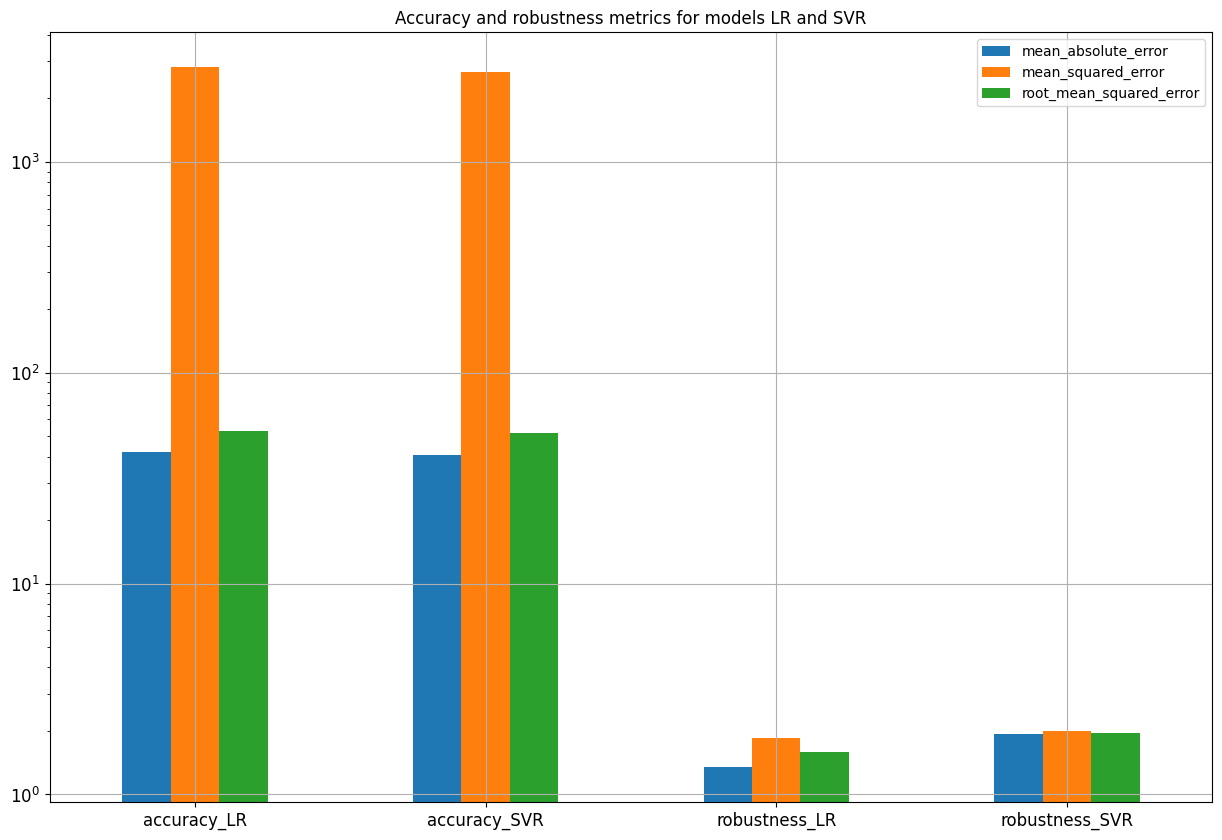

In [16]:
ax = metrics.plot.bar(
    rot=0,
    title='Accuracy and robustness metrics for models LR and SVR',
    figsize=(15,10),
    fontsize=12,
    logy=True,
    grid=True
)

lims = [
    np.min([ax.get_xlim(), ax.get_ylim()]),  # min of both axes
    np.max([ax.get_xlim(), ax.get_ylim()]),  # max of both axes
]

#ax.hlines(y=1.0, xmin=lims[0], xmax=lims[1])